# 2주차 · 비슷한 공정 묶기

**이번 실습:** 공정 조건이 비슷한 기록을 K-means로 묶고 그림으로 확인합니다.  
**준비:** 00 환경 확인, 01 파이썬 첫걸음, 02 데이터 안내

이 파일 하나를 위에서부터 순서대로 실행합니다. 주차 안의 이론 차시마다 별도 코드를 실행할 필요는 없습니다. 오른쪽 위 커널은 **Python (semi-ai)**로 고릅니다. `#` 뒤의 한국어 주석을 한 줄씩 읽고 실행해 주세요. 데이터는 교육용 합성 자료입니다.

## 0. 실습 폴더 준비

VS Code와 Colab 어디서 열어도 `data` 폴더를 찾도록 실습 폴더 위치를 정합니다. Colab에서는 처음 한 번 실습 자료를 내려받습니다.

In [ ]:
import sys, subprocess  # 실행 환경 확인과 명령 실행 도구입니다.
from pathlib import Path  # 파일 위치 도구입니다.
if "google.colab" in sys.modules:  # Colab에서 실행 중이라면
    folder = Path("/content/semiconductor_ai_beginner")  # 실습 자료를 둘 위치입니다.
    if not folder.exists():  # 아직 내려받지 않았다면
        subprocess.run(["git", "clone", "-q", "https://github.com/SeokJH-TAs/semiconductor_ai_beginner.git", str(folder)], check=True)  # 실습 자료 전체를 내려받습니다.
else:  # VS Code 등 내 컴퓨터에서 실행 중이라면
    folder = Path.cwd()  # 현재 폴더입니다.
    if folder.name == "notebooks":  # 노트북 폴더 안이라면
        folder = folder.parent  # 실습 전체 폴더로 올라갑니다.
print(folder)  # 실습 폴더 위치를 확인합니다.

## 1. 군집용 데이터 열기

clusters.csv는 온도와 압력이 세 덩어리를 이루도록 만든 90행의 교육용 데이터입니다. 정답 라벨을 넣지 않았습니다.

먼저 주석을 한 줄씩 읽고, 결과를 예상한 다음 실행해 주세요.

In [1]:
from pathlib import Path  # 파일 위치 도구입니다.
import pandas as pd  # 표 도구입니다.
data = pd.read_csv(folder / "data" / "clusters.csv")  # 군집 연습 표를 읽습니다.
print(data.head())  # 첫 다섯 행을 봅니다.

   temperature_c  pressure_torr
0        386.303          0.997
1        384.982          1.056
2        386.026          1.139
3        384.162          1.077
4        389.459          1.113


**실행 후 확인:** 온도와 압력, 두 열이 나옵니다.

## 1-1. 군집화 이전 그림

모델을 만들기 전에 원본 표부터 봅니다. 점 하나는 공정 기록 한 행입니다. 아직 군집 번호가 없으므로 모든 점을 같은 색으로 그립니다. 뒤의 4번 그림과 점의 위치가 같은지 비교해 보세요.

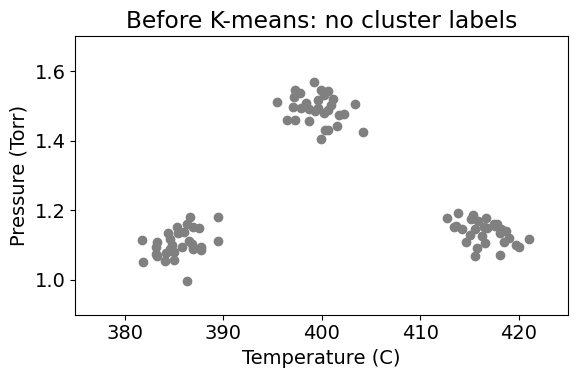

In [2]:
import matplotlib.pyplot as plt  # 그래프를 그리는 도구입니다.
plt.rcParams["font.size"] = 14  # 발표 화면에서도 축 글자를 읽기 쉽게 키웁니다.
plt.figure(figsize=(6, 4))  # 가로 6, 세로 4 크기의 그림입니다.
plt.scatter(data["temperature_c"], data["pressure_torr"], color="gray")  # 모두 같은 색으로 찍습니다.
plt.xlim(375, 425)  # 전후 그림의 온도 범위를 맞춥니다.
plt.ylim(0.9, 1.7)  # 전후 그림의 압력 범위를 맞춥니다.
plt.xlabel("Temperature (C)")  # 가로축은 온도입니다.
plt.ylabel("Pressure (Torr)")  # 세로축은 압력입니다.
plt.title("Before K-means: no cluster labels")  # 아직 군집 번호가 없습니다.
plt.tight_layout()  # 축 이름이 잘리지 않게 정리합니다.
plt.show()  # 그림을 보여 줍니다.

**비교할 내용:** 군집화는 점의 온도·압력을 바꾸지 않습니다. 점에 묶음 번호를 붙입니다. 사람 눈으로 덩어리가 보이는지 먼저 살펴보세요.

## 2. 크기 기준 맞추기

온도 숫자는 약 400이고 압력 숫자는 약 1입니다. 원래 숫자 크기만으로 거리를 계산하면 온도 차이가 압도하기 쉽습니다.

먼저 주석을 한 줄씩 읽고, 결과를 예상한 다음 실행해 주세요.

In [3]:
from sklearn.preprocessing import StandardScaler  # 평균 0, 표준편차 1로 맞추는 도구입니다.
scaler = StandardScaler()  # 표준화 도구를 준비합니다.
scaled = scaler.fit_transform(data)  # 이 표의 평균과 퍼짐을 배우고 숫자 크기를 맞춥니다.
print(scaled[:3])  # 앞에서 세 행만 봅니다. :3은 처음부터 세 개라는 뜻입니다.

[[-1.1070983  -1.38513391]
 [-1.20969594 -1.0555027 ]
 [-1.12861197 -0.59178423]]


**실행 후 확인:** 표준화 뒤 음수는 평균보다 작다는 뜻입니다. 오류가 아닙니다.

## 3. 세 묶음 찾기

K-means는 점들을 가까운 중심으로 묶고 중심을 다시 구하는 일을 반복합니다. 이번 표 전체를 탐색하는 목적이므로 전체 표로 표준화합니다.

먼저 주석을 한 줄씩 읽고, 결과를 예상한 다음 실행해 주세요.

In [4]:
from sklearn.cluster import KMeans  # 가까운 점을 묶는 도구입니다.
model = KMeans(n_clusters=3, random_state=42, n_init=10)  # 세 묶음, 시작 규칙 42, 시작점 10회 비교입니다.
labels = model.fit_predict(scaled)  # 중심을 배우고 각 행의 묶음 번호를 붙입니다.
result = data.copy()  # 원본을 남기고 사본을 만듭니다.
result["cluster"] = labels  # 사본에 군집 번호 열을 더합니다.
print(result.groupby("cluster").mean())  # 묶음별 평균 온도와 압력을 봅니다.

         temperature_c  pressure_torr
cluster                              
0           399.598433       1.491700
1           416.594733       1.137400
2           385.479300       1.105667


**실행 후 확인:** 서로 다른 세 묶음의 평균이 나옵니다. 번호 순서는 바뀔 수 있습니다.

## 4. 군집화 이후 그림

1-1번에서 본 점과 같은 점입니다. 이번에는 K-means가 붙인 번호로 색을 칠합니다. 두 그림의 축 범위를 같게 두어 점의 위치를 비교합니다. 군집 번호는 품질 등급이 아닙니다.

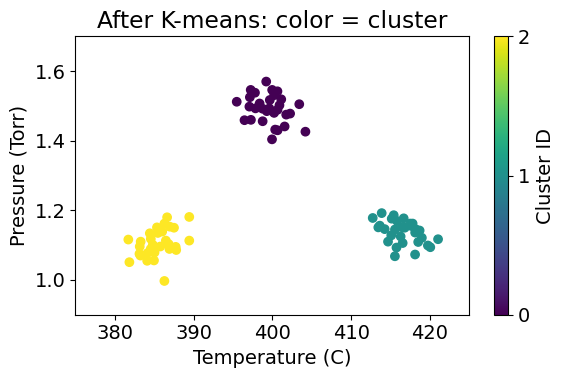

In [5]:
import matplotlib.pyplot as plt  # 그래프 도구입니다.
plt.figure(figsize=(6, 4))  # 이전 그림과 같은 크기로 만듭니다.
plt.scatter(data["temperature_c"], data["pressure_torr"], c=labels, cmap="viridis")  # 군집별 색입니다.
plt.xlim(375, 425)  # 이전 그림과 같은 온도 범위입니다.
plt.ylim(0.9, 1.7)  # 이전 그림과 같은 압력 범위입니다.
plt.xlabel("Temperature (C)")  # 가로축 이름입니다.
plt.ylabel("Pressure (Torr)")  # 세로축 이름입니다.
plt.title("After K-means: color = cluster")  # 색으로 묶음을 보여 줍니다.
plt.colorbar(ticks=range(model.n_clusters), label="Cluster ID")  # 군집 수에 맞춰 번호와 색을 보여 줍니다.
plt.tight_layout()  # 글자가 그림 밖으로 잘리지 않게 정리합니다.
plt.show()  # 완성한 그림을 보여 줍니다.

**실행 후 확인:** 세 덩어리의 점들이 보입니다. 그래프 영문 표기는 운영체제별 한글 글꼴 문제를 줄이기 위한 것입니다.

## 직접 바꾸기

3번 구역의 `n_clusters=3`을 2로 바꾸고 위에서부터 다시 실행하세요. 점의 위치는 같은데 색 묶음이 어떻게 바뀌나요? 군집 번호가 정상·불량 정답은 아니라는 점을 설명해 보세요.

**해설:** 2묶음으로 합쳐집니다. 군집은 닮은 기록의 묶음이며 실제 공정 원인이나 품질 등급을 보장하지 않습니다.

## 선택 실습 · 센서 세 개를 하나로 압축하기

**여기부터는 필수가 아닙니다.** PCA 설명을 듣고 압축·복원 오차를 직접 보고 싶은 경우에만 진행합니다. K-means 실습을 끝냈다면 수업을 여기서 마쳐도 됩니다. 아래 선택 구역은 자체 센서 표를 다시 읽습니다.

### 선택 1. 참조 센서 표 읽기

sensors.csv는 세 센서가 함께 움직이도록 만든 120행입니다. 여기서는 정상 참조 집합이라고 가정합니다. 실제 정상 판정 기준을 검증한 자료는 아닙니다.

먼저 주석을 한 줄씩 읽고, 결과를 예상한 다음 실행해 주세요.

In [6]:
from pathlib import Path  # 파일 위치 도구입니다.
import pandas as pd  # 표 도구입니다.
reference = pd.read_csv(folder / "data" / "sensors.csv")  # 참조 센서 기록입니다.
check = pd.read_csv(folder / "data" / "sensor_check.csv")  # 새로 확인할 기록 두 개입니다.

**실행 후 확인:** reference는 (120, 3), check는 (2, 3)인 표입니다.

### 선택 2. 압축 방향 배우기

새 기록 check는 평균과 압축 방향을 배우는 데 쓰지 않습니다. 새로운 기록에도 같은 자를 적용해야 비교가 됩니다.

먼저 주석을 한 줄씩 읽고, 결과를 예상한 다음 실행해 주세요.

In [7]:
from sklearn.preprocessing import StandardScaler  # 크기 기준을 맞추는 도구입니다.
from sklearn.decomposition import PCA  # 압축 방향을 찾는 도구입니다.
scaler = StandardScaler()  # 표준화 도구를 만듭니다.
normal = scaler.fit_transform(reference)  # 참조 표로만 평균과 퍼짐을 배웁니다.
pca = PCA(n_components=1)  # 주성분 한 개를 남깁니다.
compressed = pca.fit_transform(normal)  # 세 숫자를 한 숫자로 압축합니다.
print(pca.explained_variance_ratio_)  # 참조 표의 퍼짐을 얼마나 보존했는지 봅니다.

[0.9895442]


**실행 후 확인:** 설명 분산 비율이 1에 가깝습니다. 분류 정확도가 아니라 퍼짐을 보존한 비율입니다.

### 선택 3. 새 기록 압축·복원

같이 움직이던 센서 중 하나만 크게 튀면 한 방향으로 잘 설명되지 않습니다. axis=1은 행마다 평균을 구하라는 뜻입니다.

먼저 주석을 한 줄씩 읽고, 결과를 예상한 다음 실행해 주세요.

In [8]:
import numpy as np  # 여러 숫자를 한꺼번에 계산하는 도구입니다.
new_scaled = scaler.transform(check)  # 배운 기준을 새 기록에 적용합니다.
new_small = pca.transform(new_scaled)  # 새 기록도 한 숫자로 줄입니다.
restored = pca.inverse_transform(new_small)  # 다시 세 숫자로 되돌립니다.
error = np.mean((new_scaled - restored) ** 2, axis=1)  # 각 행의 표준화 공간 복원 MSE입니다.
print(error)  # 두 기록의 복원 오차를 비교합니다.

[2.53664526e-04 2.09087154e+01]


**실행 후 확인:** 두 번째 기록의 복원 오차가 첫 번째보다 훨씬 큽니다.

### 선택 4. 이상 후보 확인

95백분위는 참조 오차의 약 95%가 그 아래에 놓이는 값입니다. 교육용 임시 임계값이며 검증된 불량 기준은 아닙니다.

먼저 주석을 한 줄씩 읽고, 결과를 예상한 다음 실행해 주세요.

In [9]:
normal_back = pca.inverse_transform(compressed)  # 참조 기록도 복원합니다.
normal_error = np.mean((normal - normal_back) ** 2, axis=1)  # 참조 복원 오차를 구합니다.
threshold = np.quantile(normal_error, 0.95)  # 참조 오차의 95백분위를 임시 기준으로 씁니다.
print(error > threshold)  # 기준보다 큰 기록을 이상 후보로 표시합니다.

[False  True]


**실행 후 확인:** 첫 번째는 False, 두 번째는 True가 예상됩니다. 이상 후보는 불량 확정이 아닙니다.